### GeoSense — NISAR Multi-Date Analysis

This notebook presents the final GeoSense analysis using NISAR L-band and S-band SAR data from 12 September 2026 and 30 October 2026.

The workflow covers:
- NISAR backscatter loading
- Water detection using a -17 dB threshold
- L-band temporal water change
- S-band temporal water change
- Combined L+S temporal analysis
- Final comparative visualizations

The analysis uses 10 m spatial-resolution raster products.

In [13]:
# ============================================================
# GeoSense
# NISAR Multi-Date Water & Temporal Change Analysis
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import rasterio
from pathlib import Path

print("GeoSense — NISAR Temporal Water Analysis")
print("12 Sep 2026 → 30 Oct 2026")

GeoSense — NISAR Temporal Water Analysis
12 Sep 2026 → 30 Oct 2026


### Technical Note

The analysis is designed to compare radar-derived water information across two observation dates and two radar frequency bands. L-band and S-band provide complementary observations, while temporal comparison identifies areas of persistent water, water loss, and newly detected water.

### 1. Input Data

Four NISAR raster datasets are used as the primary inputs:

- 12 Sep 2026 — L-band
- 30 Oct 2026 — L-band
- 12 Sep 2026 — S-band
- 30 Oct 2026 — S-band

All datasets are selected from the GeoSense processing outputs.

In [14]:
# ============================================================
# 1. INPUT DATA
# ============================================================

PROJECT_DIR = Path(
    r"C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training"
)

OUTPUT_DIR = PROJECT_DIR / "outputs" / "module_08_visualization"

# L-band
SEP12_L = next(
    OUTPUT_DIR.glob("NISAR_LSAR_098_014_A_20260912/HHHH.tif")
)

OCT30_L = next(
    OUTPUT_DIR.glob("NISAR_LSAR_098_014_A_20261030/HHHH.tif")
)

# S-band
SEP12_S = next(
    OUTPUT_DIR.glob("NISAR_SSAR_098_014_A_20260912/HHHH.tif")
)

OCT30_S = next(
    OUTPUT_DIR.glob("NISAR_SSAR_098_014_A_20261030/HHHH.tif")
)

print("Input datasets:")
print("12 Sep L-band:", SEP12_L)
print("30 Oct L-band:", OCT30_L)
print("12 Sep S-band:", SEP12_S)
print("30 Oct S-band:", OCT30_S)

Input datasets:
12 Sep L-band: C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\outputs\module_08_visualization\NISAR_LSAR_098_014_A_20260912\HHHH.tif
30 Oct L-band: C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\outputs\module_08_visualization\NISAR_LSAR_098_014_A_20261030\HHHH.tif
12 Sep S-band: C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\outputs\module_08_visualization\NISAR_SSAR_098_014_A_20260912\HHHH.tif
30 Oct S-band: C:\Users\D. Sri Shashank\Desktop\Geosense\nisar-polarimetric-training\outputs\module_08_visualization\NISAR_SSAR_098_014_A_20261030\HHHH.tif


### Technical Note

Using the same acquisition area and corresponding dates allows the analysis to compare water extent and temporal changes consistently. The L-band and S-band datasets are processed separately before being combined for multi-frequency analysis.

### 2. Load and Convert NISAR Backscatter

The selected NISAR HHHH raster products are loaded using Rasterio.

The stored linear backscatter values are converted into decibels using:

**dB = 10 × log10(backscatter)**

The raster dimensions, coordinate reference system, and spatial metadata are also retained.

In [15]:
# ============================================================
# 2. LOAD NISAR BACKSCATTER DATA
# ============================================================

def load_nisar_db(path):
    with rasterio.open(path) as src:
        data = src.read(1).astype(np.float32)
        profile = src.profile
        transform = src.transform
        crs = src.crs

    # Convert linear backscatter to dB
    data = 10 * np.log10(np.maximum(data, 1e-10))

    return data, profile, transform, crs


sep12_l_db, l_profile, l_transform, l_crs = load_nisar_db(SEP12_L)
oct30_l_db, _, _, _ = load_nisar_db(OCT30_L)

sep12_s_db, s_profile, s_transform, s_crs = load_nisar_db(SEP12_S)
oct30_s_db, _, _, _ = load_nisar_db(OCT30_S)

print("L-band shape:", sep12_l_db.shape)
print("S-band shape:", sep12_s_db.shape)

print("L-band CRS:", l_crs)
print("S-band CRS:", s_crs)

L-band shape: (2006, 2126)
S-band shape: (2006, 2126)
L-band CRS: EPSG:32645
S-band CRS: EPSG:32645


### Technical Note

Working in decibels makes the radar backscatter values easier to interpret and provides a consistent scale for applying the water-detection threshold.

The resulting L-band and S-band arrays are used throughout the remaining analysis.

### 3. Water Detection

A threshold of **-17 dB** is used to identify candidate water pixels.

Pixels with backscatter below the threshold are classified as water:

**Water = backscatter < -17 dB**

The same threshold is applied consistently to both dates and both radar bands.

In [16]:
# ============================================================
# 3. WATER DETECTION
# ============================================================

WATER_THRESHOLD = -17  # dB

# Create water masks
sep12_l_water = sep12_l_db < WATER_THRESHOLD
oct30_l_water = oct30_l_db < WATER_THRESHOLD

sep12_s_water = sep12_s_db < WATER_THRESHOLD
oct30_s_water = oct30_s_db < WATER_THRESHOLD

print(f"Water threshold: {WATER_THRESHOLD} dB")

print("\nL-band water extent:")
print(f"12 Sep: {np.sum(sep12_l_water):,} pixels")
print(f"30 Oct: {np.sum(oct30_l_water):,} pixels")

print("\nS-band water extent:")
print(f"12 Sep: {np.sum(sep12_s_water):,} pixels")
print(f"30 Oct: {np.sum(oct30_s_water):,} pixels")

Water threshold: -17 dB

L-band water extent:
12 Sep: 902,845 pixels
30 Oct: 431,898 pixels

S-band water extent:
12 Sep: 853,617 pixels
30 Oct: 317,133 pixels


### Technical Note

The -17 dB threshold provides a common rule for comparing the two acquisition dates. The resulting binary masks form the basis for both the water-extent analysis and the temporal-change analysis.

### 4. L-band Temporal Water Change

The L-band water masks from 12 September and 30 October are compared pixel-by-pixel.

Each pixel is classified as:

- **0 — No change / non-water**
- **1 — Persistent water**
- **2 — Water receded / water loss**
- **3 — New water**

In [17]:
# ============================================================
# 4. L-Band TEMPORAL WATER CHANGE
# ============================================================

# 0 = No change
# 1 = Persistent water
# 2 = Water receded
# 3 = New water

l_temporal_change = np.zeros_like(sep12_l_water, dtype=np.uint8)

l_temporal_change[
    sep12_l_water & oct30_l_water
] = 1

l_temporal_change[
    sep12_l_water & ~oct30_l_water
] = 2

l_temporal_change[
    ~sep12_l_water & oct30_l_water
] = 3

print("=" * 60)
print("L-BAND TEMPORAL WATER CHANGE")
print("=" * 60)

total = l_temporal_change.size

persistent = np.sum(l_temporal_change == 1)
receded = np.sum(l_temporal_change == 2)
new_water = np.sum(l_temporal_change == 3)

print(f"Persistent water : {persistent:,} pixels ({100*persistent/total:.2f}%)")
print(f"Water receded    : {receded:,} pixels ({100*receded/total:.2f}%)")
print(f"New water        : {new_water:,} pixels ({100*new_water/total:.2f}%)")

L-BAND TEMPORAL WATER CHANGE
Persistent water : 227,517 pixels (5.33%)
Water receded    : 675,328 pixels (15.84%)
New water        : 204,381 pixels (4.79%)


### Technical Note

This comparison converts two independent water masks into a temporal-change product. It allows GeoSense to identify where water remained present, disappeared, or appeared between the two observation dates.

### 5. L-band Temporal Change Map

The L-band temporal classification is visualized spatially to show the distribution of persistent water, water loss, and newly detected water between the two dates.

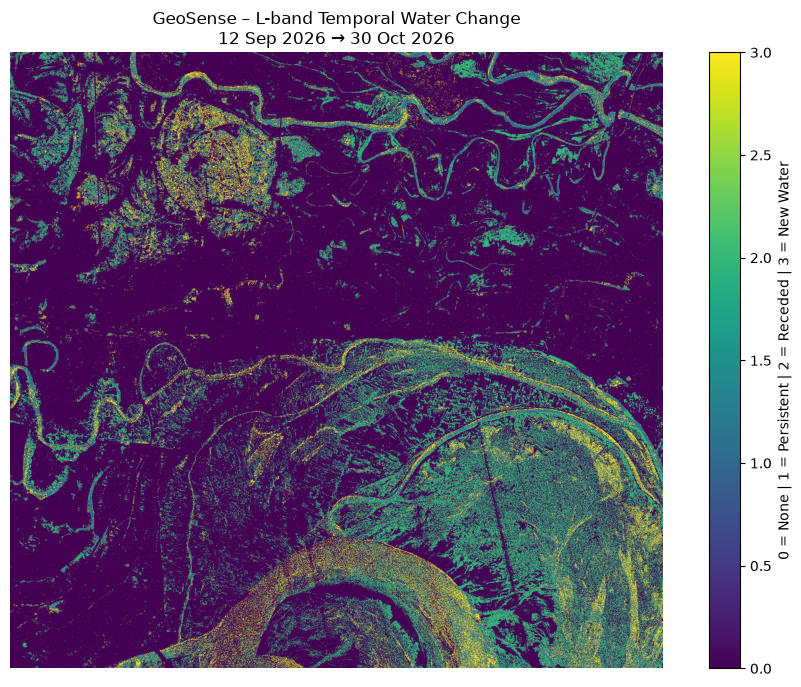

In [18]:
# ============================================================
# 5. L-BAND TEMPORAL CHANGE MAP
# ============================================================

plt.figure(figsize=(12, 8))

plt.imshow(
    l_temporal_change,
    cmap="viridis",
    vmin=0,
    vmax=3
)

plt.title(
    "GeoSense – L-band Temporal Water Change\n"
    "12 Sep 2026 → 30 Oct 2026"
)

plt.axis("off")

plt.colorbar(
    label="0 = None | 1 = Persistent | 2 = Receded | 3 = New Water"
)

plt.show()

### Technical Note

The map provides the first spatial visualization of temporal water dynamics. It can be used to identify areas requiring closer inspection in the navigation decision-support workflow.

### 6. S-band Temporal Water Change

The same temporal-change classification is independently applied to the S-band observations.

Classification:

- **0 — No change / non-water**
- **1 — Persistent water**
- **2 — Water receded / water loss**
- **3 — New water**

In [19]:
# ============================================================
# 6. S-BAND TEMPORAL WATER CHANGE
# ============================================================

# 0 = No change
# 1 = Persistent water
# 2 = Water receded
# 3 = New water

s_temporal_change = np.zeros_like(sep12_s_water, dtype=np.uint8)

s_temporal_change[
    sep12_s_water & oct30_s_water
] = 1

s_temporal_change[
    sep12_s_water & ~oct30_s_water
] = 2

s_temporal_change[
    ~sep12_s_water & oct30_s_water
] = 3

print("=" * 60)
print("S-BAND TEMPORAL WATER CHANGE")
print("=" * 60)

total = s_temporal_change.size

persistent = np.sum(s_temporal_change == 1)
receded = np.sum(s_temporal_change == 2)
new_water = np.sum(s_temporal_change == 3)

print(
    f"Persistent water : {persistent:,} pixels "
    f"({100*persistent/total:.2f}%)"
)

print(
    f"Water receded    : {receded:,} pixels "
    f"({100*receded/total:.2f}%)"
)

print(
    f"New water        : {new_water:,} pixels "
    f"({100*new_water/total:.2f}%)"
)

S-BAND TEMPORAL WATER CHANGE
Persistent water : 166,409 pixels (3.90%)
Water receded    : 687,208 pixels (16.11%)
New water        : 150,724 pixels (3.53%)


### Technical Note

Processing S-band independently provides a second radar-frequency perspective on the same temporal interval. This helps evaluate whether the observed water patterns are also detected in the S-band observations.

### 7. S-band Temporal Change Map

The S-band temporal classifications are visualized as a spatial change map for the 12 September → 30 October observation period.

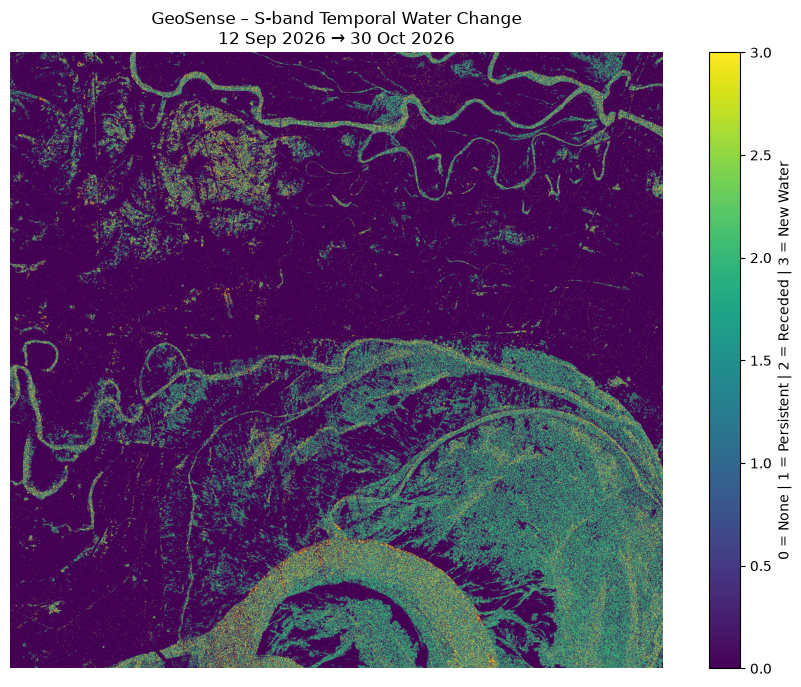

In [20]:
# ============================================================
# 7. S-BAND TEMPORAL CHANGE MAP
# ============================================================

plt.figure(figsize=(12, 8))

plt.imshow(
    s_temporal_change,
    cmap="viridis",
    vmin=0,
    vmax=3
)

plt.title(
    "GeoSense – S-band Temporal Water Change\n"
    "12 Sep 2026 → 30 Oct 2026"
)

plt.axis("off")

plt.colorbar(
    label="0 = None | 1 = Persistent | 2 = Receded | 3 = New Water"
)

plt.show()

### Technical Note

The S-band map complements the L-band temporal map. Comparing the two frequency-specific products provides a more complete view of radar-observed water dynamics.

### 8. Combined L+S Temporal Water Analysis

L-band and S-band water masks are fused using an **OR-based rule**:

**Combined water = L-band water OR S-band water**

This produces a multi-frequency water mask for each observation date.

The combined masks are then compared temporally using the same four-class change scheme.

COMBINED L+S WATER FUSION
12 Sep combined water : 1,305,293 pixels (30.61%)
30 Oct combined water : 572,574 pixels (13.43%)

Fusion rule: L-band OR S-band

COMBINED L+S TEMPORAL WATER CHANGE
Persistent water : 414,026 pixels (9.71%)
Water receded    : 891,267 pixels (20.90%)
New water        : 158,548 pixels (3.72%)


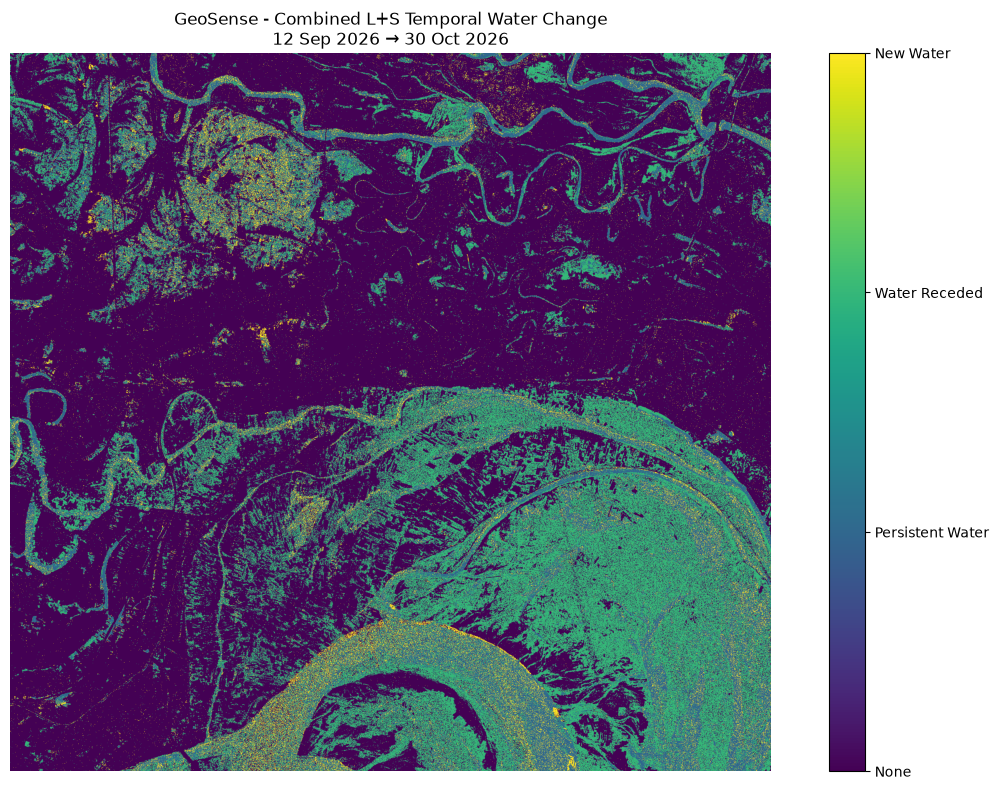

In [22]:
# ============================================================
# 8. COMBINED L+S TEMPORAL WATER CHANGE
# ============================================================

THRESHOLD = -17

# ------------------------------------------------------------
# 1. Create L+S water masks for each date
# ------------------------------------------------------------

sep12_l_water = sep12_l_db < THRESHOLD
sep12_s_water = sep12_s_db < THRESHOLD

oct30_l_water = oct30_l_db < THRESHOLD
oct30_s_water = oct30_s_db < THRESHOLD


# ------------------------------------------------------------
# 2. L+S FUSION
# A pixel is considered water if detected by EITHER
# L-band OR S-band
# ------------------------------------------------------------

sep12_ls_water = sep12_l_water | sep12_s_water
oct30_ls_water = oct30_l_water | oct30_s_water


# ------------------------------------------------------------
# 3. Combined water extent
# ------------------------------------------------------------

total = sep12_ls_water.size

sep12_combined = np.sum(sep12_ls_water)
oct30_combined = np.sum(oct30_ls_water)

print("=" * 60)
print("COMBINED L+S WATER FUSION")
print("=" * 60)

print(
    f"12 Sep combined water : {sep12_combined:,} pixels "
    f"({100 * sep12_combined / total:.2f}%)"
)

print(
    f"30 Oct combined water : {oct30_combined:,} pixels "
    f"({100 * oct30_combined / total:.2f}%)"
)

print("\nFusion rule: L-band OR S-band")


# ------------------------------------------------------------
# 4. TEMPORAL CHANGE
#
# 0 = No water
# 1 = Persistent water
# 2 = Water receded
# 3 = New water
# ------------------------------------------------------------

ls_temporal_change = np.zeros_like(sep12_ls_water, dtype=np.uint8)

# Persistent water
ls_temporal_change[
    sep12_ls_water & oct30_ls_water
] = 1

# Water receded
ls_temporal_change[
    sep12_ls_water & ~oct30_ls_water
] = 2

# New water
ls_temporal_change[
    ~sep12_ls_water & oct30_ls_water
] = 3


# ------------------------------------------------------------
# 5. Statistics
# ------------------------------------------------------------

persistent = np.sum(ls_temporal_change == 1)
receded = np.sum(ls_temporal_change == 2)
new_water = np.sum(ls_temporal_change == 3)

print("\n" + "=" * 60)
print("COMBINED L+S TEMPORAL WATER CHANGE")
print("=" * 60)

print(
    f"Persistent water : {persistent:,} pixels "
    f"({100 * persistent / total:.2f}%)"
)

print(
    f"Water receded    : {receded:,} pixels "
    f"({100 * receded / total:.2f}%)"
)

print(
    f"New water        : {new_water:,} pixels "
    f"({100 * new_water / total:.2f}%)"
)


# ------------------------------------------------------------
# 6. VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(12, 8))

plt.imshow(
    ls_temporal_change,
    cmap="viridis",
    vmin=0,
    vmax=3
)

plt.title(
    "GeoSense - Combined L+S Temporal Water Change\n"
    "12 Sep 2026 → 30 Oct 2026"
)

plt.axis("off")

cbar = plt.colorbar()
cbar.set_ticks([0, 1, 2, 3])
cbar.set_ticklabels([
    "None",
    "Persistent Water",
    "Water Receded",
    "New Water"
])

plt.tight_layout()
plt.show()

### Technical Note

The L+S fusion increases the opportunity to detect water using either radar frequency. The resulting temporal product provides a multi-frequency view of persistent water, water loss, and newly detected water.

This is the principal multi-sensor component of the GeoSense analysis.

### Final GeoSense Results Summary

This section consolidates the numerical outputs from the L-band, S-band, and combined L+S analyses.

It reports:

- Water extent for both dates
- L-band temporal change
- S-band temporal change
- Combined L+S temporal change
- Detection threshold
- Spatial resolution
- Scene dimensions

In [23]:
# ============================================================
# FINAL GEOSENSE RESULTS SUMMARY
# ============================================================

THRESHOLD = -17

# Recreate masks directly from the already-loaded dB arrays
sep12_l_water = sep12_l_db < THRESHOLD
oct30_l_water = oct30_l_db < THRESHOLD

sep12_s_water = sep12_s_db < THRESHOLD
oct30_s_water = oct30_s_db < THRESHOLD

# L+S fusion: water detected by either frequency
sep12_ls_water = sep12_l_water | sep12_s_water
oct30_ls_water = oct30_l_water | oct30_s_water

# L-band temporal change
l_temporal = np.zeros_like(sep12_l_water, dtype=np.uint8)
l_temporal[sep12_l_water & oct30_l_water] = 1
l_temporal[sep12_l_water & ~oct30_l_water] = 2
l_temporal[~sep12_l_water & oct30_l_water] = 3

# S-band temporal change
s_temporal = np.zeros_like(sep12_s_water, dtype=np.uint8)
s_temporal[sep12_s_water & oct30_s_water] = 1
s_temporal[sep12_s_water & ~oct30_s_water] = 2
s_temporal[~sep12_s_water & oct30_s_water] = 3

# Combined L+S temporal change
ls_temporal = np.zeros_like(sep12_ls_water, dtype=np.uint8)
ls_temporal[sep12_ls_water & oct30_ls_water] = 1
ls_temporal[sep12_ls_water & ~oct30_ls_water] = 2
ls_temporal[~sep12_ls_water & oct30_ls_water] = 3

def pct(mask):
    return 100 * np.sum(mask) / mask.size

print("=" * 65)
print("GEOSENSE FINAL RESULTS")
print("=" * 65)

print("\nWATER EXTENT")
print("-" * 65)
print(f"L-band  | 12 Sep: {np.sum(sep12_l_water):,} px ({pct(sep12_l_water):.2f}%)")
print(f"L-band  | 30 Oct: {np.sum(oct30_l_water):,} px ({pct(oct30_l_water):.2f}%)")
print(f"S-band  | 12 Sep: {np.sum(sep12_s_water):,} px ({pct(sep12_s_water):.2f}%)")
print(f"S-band  | 30 Oct: {np.sum(oct30_s_water):,} px ({pct(oct30_s_water):.2f}%)")
print(f"L+S     | 12 Sep: {np.sum(sep12_ls_water):,} px ({pct(sep12_ls_water):.2f}%)")
print(f"L+S     | 30 Oct: {np.sum(oct30_ls_water):,} px ({pct(oct30_ls_water):.2f}%)")

print("\nL-BAND TEMPORAL CHANGE")
print("-" * 65)
print(f"Persistent water : {np.sum(l_temporal == 1):,} px")
print(f"Water loss       : {np.sum(l_temporal == 2):,} px")
print(f"New water        : {np.sum(l_temporal == 3):,} px")

print("\nS-BAND TEMPORAL CHANGE")
print("-" * 65)
print(f"Persistent water : {np.sum(s_temporal == 1):,} px")
print(f"Water loss       : {np.sum(s_temporal == 2):,} px")
print(f"New water        : {np.sum(s_temporal == 3):,} px")

print("\nCOMBINED L+S TEMPORAL CHANGE")
print("-" * 65)
print(f"Persistent water : {np.sum(ls_temporal == 1):,} px")
print(f"Water loss       : {np.sum(ls_temporal == 2):,} px")
print(f"New water        : {np.sum(ls_temporal == 3):,} px")

print("\nThreshold used:", THRESHOLD, "dB")
print("Spatial resolution: 10 m")
print("Scene dimensions:", sep12_l_db.shape)

GEOSENSE FINAL RESULTS

WATER EXTENT
-----------------------------------------------------------------
L-band  | 12 Sep: 902,845 px (21.17%)
L-band  | 30 Oct: 431,898 px (10.13%)
S-band  | 12 Sep: 853,617 px (20.02%)
S-band  | 30 Oct: 317,133 px (7.44%)
L+S     | 12 Sep: 1,305,293 px (30.61%)
L+S     | 30 Oct: 572,574 px (13.43%)

L-BAND TEMPORAL CHANGE
-----------------------------------------------------------------
Persistent water : 227,517 px
Water loss       : 675,328 px
New water        : 204,381 px

S-BAND TEMPORAL CHANGE
-----------------------------------------------------------------
Persistent water : 166,409 px
Water loss       : 687,208 px
New water        : 150,724 px

COMBINED L+S TEMPORAL CHANGE
-----------------------------------------------------------------
Persistent water : 414,026 px
Water loss       : 891,267 px
New water        : 158,548 px

Threshold used: -17 dB
Spatial resolution: 10 m
Scene dimensions: (2006, 2126)


### Technical Note

This summary provides a single numerical reference point for the final results and makes the outputs easier to transfer into the project report, presentation, and decision-support discussion.

### Final Water-Mapping Comparison

The six binary water products are displayed together:

**12 September**
- L-band
- S-band
- Combined L+S

**30 October**
- L-band
- S-band
- Combined L+S

This allows direct visual comparison of water extent across dates and radar bands.

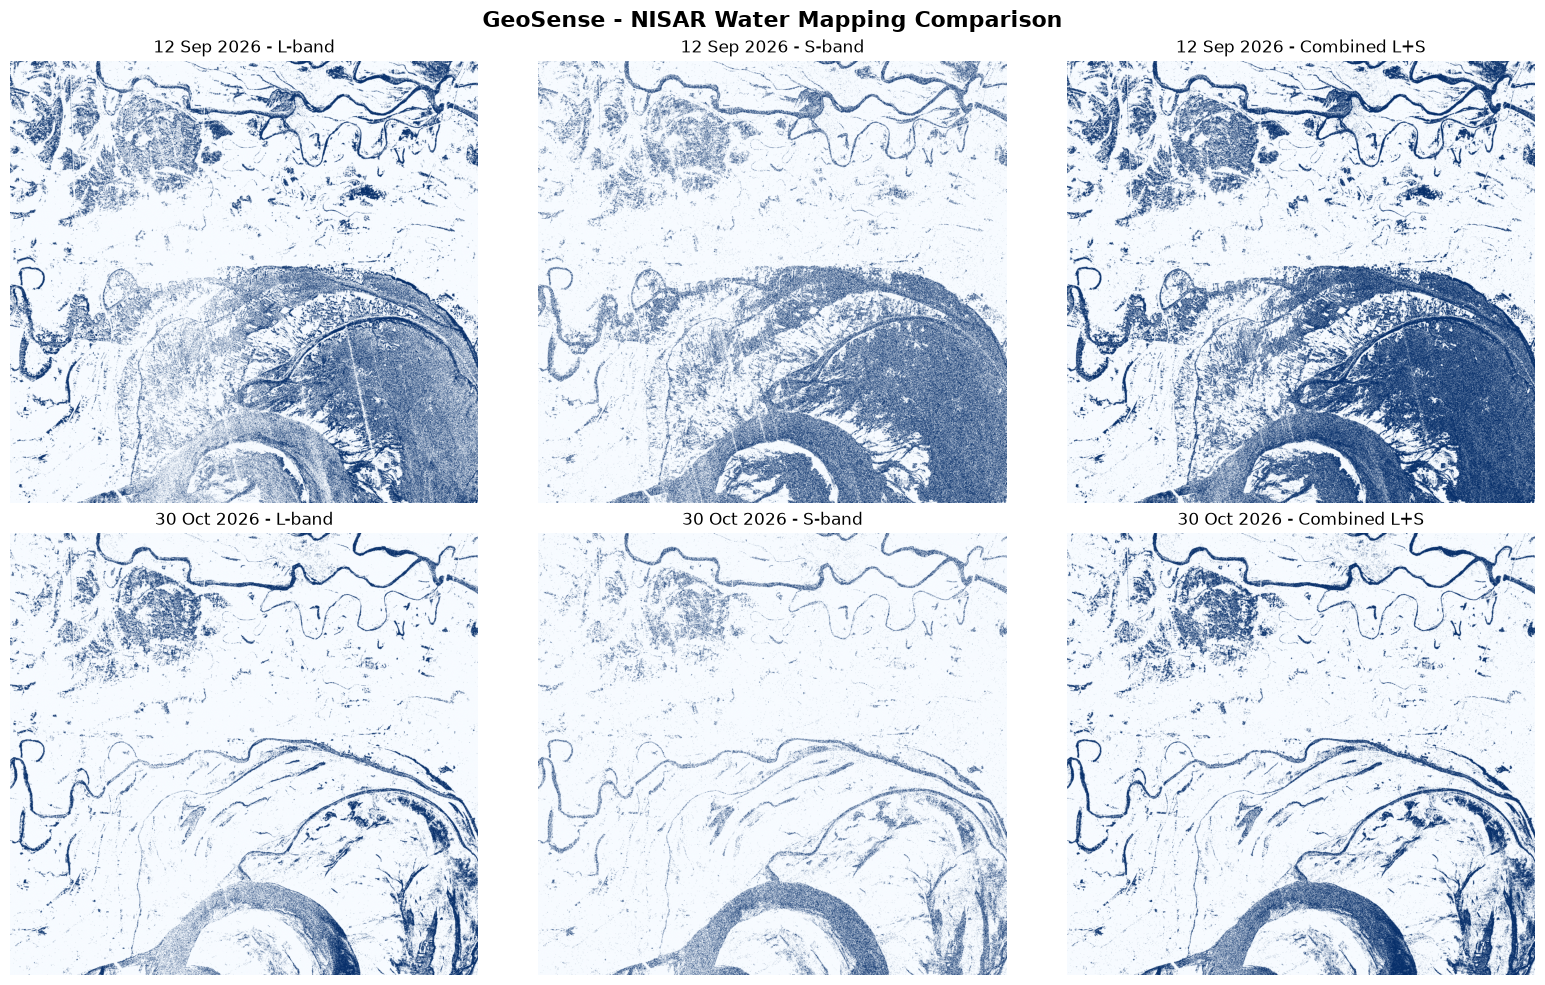

In [24]:
# ============================================================
# FINAL WATER-MAPPING COMPARISON
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

images = [
    sep12_l_water,
    sep12_s_water,
    sep12_ls_water,
    oct30_l_water,
    oct30_s_water,
    oct30_ls_water
]

titles = [
    "12 Sep 2026 - L-band",
    "12 Sep 2026 - S-band",
    "12 Sep 2026 - Combined L+S",
    "30 Oct 2026 - L-band",
    "30 Oct 2026 - S-band",
    "30 Oct 2026 - Combined L+S"
]

for ax, img, title in zip(axes.ravel(), images, titles):
    ax.imshow(img, cmap="Blues")
    ax.set_title(title, fontsize=12)
    ax.axis("off")

fig.suptitle(
    "GeoSense - NISAR Water Mapping Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Technical Note

The six-panel comparison provides a compact overview of how the detected water distribution changes between the two observation dates and how the L+S fusion compares with the individual radar bands.

### Final Temporal Change Comparison

The final temporal products are presented side-by-side:

1. L-band temporal change
2. S-band temporal change
3. Combined L+S temporal change

A common legend is used to maintain consistent interpretation across all three maps.

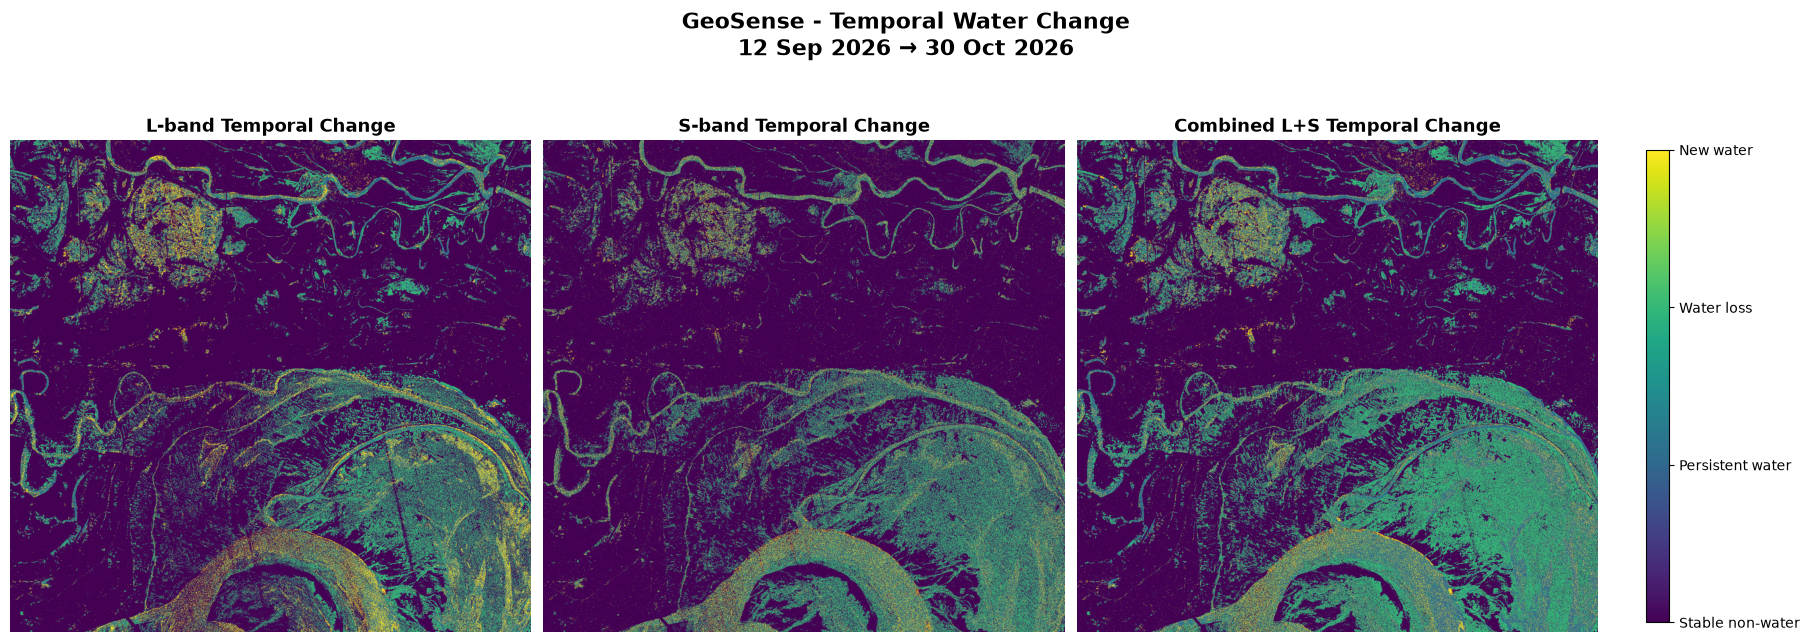

In [27]:
# ============================================================
# FINAL TEMPORAL CHANGE COMPARISON
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 7),
    constrained_layout=True
)

maps = [
    l_temporal,
    s_temporal,
    ls_temporal
]

titles = [
    "L-band Temporal Change",
    "S-band Temporal Change",
    "Combined L+S Temporal Change"
]

for ax, change_map, title in zip(axes, maps, titles):

    im = ax.imshow(
        change_map,
        cmap="viridis",
        vmin=0,
        vmax=3
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.axis("off")

fig.suptitle(
    "GeoSense - Temporal Water Change\n"
    "12 Sep 2026 → 30 Oct 2026",
    fontsize=16,
    fontweight="bold"
)

# Put ONE clean colorbar outside all three plots
cbar = fig.colorbar(
    im,
    ax=axes,
    location="right",
    shrink=0.75,
    pad=0.03
)

cbar.set_ticks([0, 1, 2, 3])
cbar.set_ticklabels([
    "Stable non-water",
    "Persistent water",
    "Water loss",
    "New water"
])

plt.show()

### Technical Note

This is the final spatial comparison of the GeoSense temporal analysis.

The three maps provide:
- A frequency-specific L-band view
- A frequency-specific S-band view
- A combined multi-frequency view

Together, they demonstrate how NISAR observations can be transformed into temporal water-change information relevant to environmental monitoring and navigation decision support.